# Run A record (Google Colab, 26 October 2026)

This is a run of `nzdf_flood_product.ipynb` with the **Run A** checkpoint (`models/checkpoints/unet_best.pt`: epoch 38, threshold 0.50). The original notebook, with the Run B outputs, is unchanged in `notebooks/nzdf_flood_product.ipynb`.

Differences from the original:

- **Setup cells at the top.** They clone the repository, download the Git LFS files (checkpoint and Gabrielle stack), copy the HBRC flood extent from Google Drive and link the files to the paths the notebook expects. The HBRC layer itself is not in the repository (HBRC supplied it on request).
- **No test-block list.** `data/dataset_patches/dataset_info.json` is not in the repository, so an empty one was created. The "Test blocks only" rows are therefore all zero and should be ignored; the reported scores are the "Whole scene" rows.
- **No road layer.** The LINZ road centrelines were not used, so the road steps print "Skipped" and the road-impact map shows flood polygons only.
- **Report map.** The last cell draws the HBRC comparison map with the code from `notebooks/gabrielle_map.ipynb`, without roads, and saves `gabrielle_flood_map_runA.png` and `.pdf` at 300 dpi.
- **Cell order.** The setup cells were moved to the top after running, so the execution numbers are out of order. In the first setup cell the HBRC copy failed (wrong Drive folder); the third setup cell copied the files, and the scoring cells were then re-run.


# Phase 5: Full-Scene Flood Map & NZDF Decision Product

Turns the trained U-Net into products the NZDF can use, in three steps:

1. **Full-scene inference.** Predicts flooding across the whole 6667 × 4330 pixel Hawke's Bay / Esk Valley scene and saves it as GeoTIFFs.
2. **Vectorisation & road overlay.** Converts the flood raster to polygons and finds road segments that are under water.
3. **External validation.** Scores the flood map against an independent flood extent, not the `baseline_mask` pseudo-label.

**Before running:**
- `outputs/unet_best.pt` must be the checkpoint from a full `unet_training.ipynb` run. The cell that loads it prints its epoch and validation IoU; check them.
- Copy `CycloneGabrielle_HawkesBay_S1_Stack_v2.tif` from Google Drive into the repository's `data/` folder.
- Steps 2 and 3 need files you download by hand (see each step). If a file is missing, that step is skipped and the rest still runs.
- Paths are relative to this notebook, so run it from `models/`.

In [1]:
# Setup for the HBRC Run A test
%cd /content
!git clone https://github.com/MusicalManiac/Coastal-Change-Detection-Using-SAR-U-Net.git
%cd /content/Coastal-Change-Detection-Using-SAR-U-Net
!git lfs install
!git lfs pull --include="models/checkpoints/unet_best.pt,data/raw/CycloneGabrielle_HawkesBay_S1_Stack_v2.tif"
!ls -lh models/checkpoints/unet_best.pt data/raw/CycloneGabrielle_HawkesBay_S1_Stack_v2.tif

from google.colab import drive
drive.mount('/content/drive')
HBRC_FOLDER = '/content/drive/MyDrive/HBRC'   # change if your folder is elsewhere

import os, json
os.makedirs('data/reference/Hawke_s_Bay_Flood_Observation_Extents', exist_ok=True)
!cp "{HBRC_FOLDER}"/Hawke_s_Bay_Flood_Observation_Extents.* data/reference/Hawke_s_Bay_Flood_Observation_Extents/

# Point the notebook at where the files actually are
!ln -sf "$PWD/data/raw/CycloneGabrielle_HawkesBay_S1_Stack_v2.tif" data/
os.makedirs('notebooks/outputs', exist_ok=True)
!ln -sf "$PWD/models/checkpoints/unet_best.pt" notebooks/outputs/unet_best.pt

# The test-area file isn't in the repo; an empty one lets the notebook run
os.makedirs('data/dataset_patches', exist_ok=True)
if not os.path.exists('data/dataset_patches/dataset_info.json'):
    json.dump({'block_size': 256, 'blocks': {'test': []}}, open('data/dataset_patches/dataset_info.json', 'w'))
%cd notebooks

/content
fatal: destination path 'Coastal-Change-Detection-Using-SAR-U-Net' already exists and is not an empty directory.
/content/Coastal-Change-Detection-Using-SAR-U-Net
Updated Git hooks.
Git LFS initialized.
-rw-r--r-- 1 root root 632M Oct 26 04:34 data/raw/CycloneGabrielle_HawkesBay_S1_Stack_v2.tif
-rw-r--r-- 1 root root  94M Oct 26 04:32 models/checkpoints/unet_best.pt
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cp: cannot stat '/content/drive/MyDrive/HBRC/Hawke_s_Bay_Flood_Observation_Extents.*': No such file or directory
/content/Coastal-Change-Detection-Using-SAR-U-Net/notebooks


In [4]:
!apt-get -qq install git-lfs
!cd .. && git lfs install && git lfs pull --include="models/checkpoints/unet_best.pt,data/raw/CycloneGabrielle_HawkesBay_S1_Stack_v2.tif"
!ls -lh ../models/checkpoints/unet_best.pt ../data/raw/CycloneGabrielle_HawkesBay_S1_Stack_v2.tif

Updated Git hooks.
Git LFS initialized.
-rw-r--r-- 1 root root 632M Oct 26 04:34 ../data/raw/CycloneGabrielle_HawkesBay_S1_Stack_v2.tif
-rw-r--r-- 1 root root  94M Oct 26 04:32 ../models/checkpoints/unet_best.pt


In [18]:
!mkdir -p ../data/reference/Hawke_s_Bay_Flood_Observation_Extents
!cp /content/drive/MyDrive/Hawke_s_Bay_Flood_Observation_Extents/* ../data/reference/Hawke_s_Bay_Flood_Observation_Extents/
!ls ../data/reference/Hawke_s_Bay_Flood_Observation_Extents/

Hawke_s_Bay_Flood_Observation_Extents.cpg
Hawke_s_Bay_Flood_Observation_Extents.dbf
Hawke_s_Bay_Flood_Observation_Extents.prj
Hawke_s_Bay_Flood_Observation_Extents.shp
Hawke_s_Bay_Flood_Observation_Extents.shx


In [2]:
# Cell 1: Install dependencies (geopandas for the vector steps; the rest is used by unet_training.ipynb)
%pip install -q geopandas segmentation-models-pytorch rasterio

In [3]:
import os
import json

import numpy as np
import pandas as pd
import torch
import rasterio
import rasterio.features
import geopandas as gpd
from shapely.geometry import box, shape
import segmentation_models_pytorch as smp
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# -------------------------------------------------------------------------
# 1. Configuration
# -------------------------------------------------------------------------
# Paths are relative to this notebook (run it from models/)
TIF_PATH = os.path.join('..', 'data', 'CycloneGabrielle_HawkesBay_S1_Stack_v2.tif')  # From data_collection.ipynb
DATASET_INFO_PATH = os.path.join('..', 'data', 'dataset_patches', 'dataset_info.json')
CHECKPOINT_PATH = os.path.join('outputs', 'unet_best.pt')

# Downloaded by hand (see Steps 2 and 3); a step is skipped if its file is missing
ROADS_PATH = os.path.join('..', 'data', 'linz', 'lds-nz-road-centrelines-topo-150k-SHP', 'nz-road-centrelines-topo-150k.shp')
REFERENCE_PATH = os.path.join('..', 'data', 'reference', 'Hawke_s_Bay_Flood_Observation_Extents', 'Hawke_s_Bay_Flood_Observation_Extents.shp')
REFERENCE_AREA_PATH = None    # Optional polygon of the area the reference actually mapped (see Step 3)

OUTPUT_DIR = os.path.join('outputs', 'nzdf')
os.makedirs(OUTPUT_DIR, exist_ok=True)

PATCH_SIZE = 256
STRIDE = 128                  # 50% overlap, as in training; overlapping predictions are blended
BATCH_SIZE = 16
MIN_POLYGON_AREA_M2 = 1000    # Drop flood polygons under 10 pixels (radar speckle)
OUTPUT_CRS = 'EPSG:2193'      # NZTM2000, the New Zealand map projection used by LINZ and councils

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')  # Apple-silicon GPU
else:
    device = torch.device('cpu')
print(f"Using device: {device}")

Using device: cuda


In [5]:
# -------------------------------------------------------------------------
# 2. Load the Trained U-Net
# -------------------------------------------------------------------------
# The checkpoint stores the encoder, input bands, normalisation and tuned threshold,
# so inference is set up exactly as in training.
checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)

model = smp.Unet(
    encoder_name=checkpoint['encoder'],
    encoder_weights=None,  # Weights come from the checkpoint
    in_channels=checkpoint['in_channels'],
    classes=1,
).to(device)
model.load_state_dict(checkpoint['model_state'])
model.eval()

INPUT_BANDS = checkpoint['input_bands']
MEAN = np.array(checkpoint['normalisation']['mean'], dtype=np.float32)
STD = np.array(checkpoint['normalisation']['std'], dtype=np.float32)
THRESHOLD = checkpoint['threshold']

print(f"Checkpoint from epoch {checkpoint['epoch']}, val IoU {checkpoint['val_iou']:.3f}, threshold {THRESHOLD:.2f}")
print(f"Input bands: {INPUT_BANDS}")
if checkpoint['val_iou'] < 0.5:
    print("WARNING: this checkpoint looks undertrained - re-run unet_training.ipynb to completion first.")

Checkpoint from epoch 38, val IoU 0.897, threshold 0.50
Input bands: ['pre_vv', 'pre_vh', 'post_vv', 'post_vh']


## Step 1: Full-Scene Inference

The scene is predicted with overlapping 256 × 256 windows, like the training patches. Three details matter for a usable map:

- **Same inputs as training.** Only the four bands the model was trained on are used, normalised with the training statistics.
- **Full coverage.** The last window in each row and column is shifted to sit flush with the scene edge, so no strip is left unpredicted.
- **No seams.** Each window's prediction is weighted down towards its edges, where the model sees less context, and overlapping windows are averaged.

In [6]:
# -------------------------------------------------------------------------
# 3. Read the Scene
# -------------------------------------------------------------------------
with rasterio.open(TIF_PATH) as src:
    profile = src.profile
    transform, crs, scene_bounds = src.transform, src.crs, src.bounds
    band_index = {name: i + 1 for i, name in enumerate(src.descriptions)}
    features = src.read([band_index[name] for name in INPUT_BANDS]).astype(np.float32)
    baseline_mask = src.read(band_index['baseline_mask'])

_, height, width = features.shape
print(f"Scene: {height} x {width} pixels, {crs}")

# Same validity rule as data_preprocessing.ipynb: nodata is -inf, and some tiles come back as all zeros
valid = np.isfinite(features).all(axis=0) & ~(features == 0).all(axis=0)
print(f"Valid pixels: {100 * valid.mean():.1f}%")

# Normalise with the training statistics; nodata pixels are set to 0 (the training mean)
features = (features - MEAN[:, None, None]) / STD[:, None, None]
features[:, ~valid] = 0

Scene: 6667 x 4330 pixels, EPSG:32760
Valid pixels: 99.7%


In [7]:
# -------------------------------------------------------------------------
# 4. Sliding-Window Inference
# -------------------------------------------------------------------------
def window_starts(size):
    """Window start positions along one axis, with the last window flush against the edge."""
    starts = list(range(0, size - PATCH_SIZE + 1, STRIDE))
    if starts[-1] != size - PATCH_SIZE:
        starts.append(size - PATCH_SIZE)
    return starts

# Each window's prediction is weighted down towards its edges before blending
ramp = np.sin(np.pi * (np.arange(PATCH_SIZE) + 0.5) / PATCH_SIZE) ** 2
window_weight = np.outer(ramp, ramp).astype(np.float32)

prob_sum = np.zeros((height, width), dtype=np.float32)
weight_sum = np.zeros((height, width), dtype=np.float32)

windows = [(y, x) for y in window_starts(height) for x in window_starts(width)
           if valid[y:y + PATCH_SIZE, x:x + PATCH_SIZE].any()]
print(f"Predicting {len(windows)} windows...")

with torch.no_grad():
    for i in range(0, len(windows), BATCH_SIZE):
        batch = windows[i:i + BATCH_SIZE]
        images = np.stack([features[:, y:y + PATCH_SIZE, x:x + PATCH_SIZE] for y, x in batch])
        probs = torch.sigmoid(model(torch.from_numpy(images).to(device)))[:, 0].cpu().numpy()
        for (y, x), prob in zip(batch, probs):
            prob_sum[y:y + PATCH_SIZE, x:x + PATCH_SIZE] += prob * window_weight
            weight_sum[y:y + PATCH_SIZE, x:x + PATCH_SIZE] += window_weight

flood_prob = np.divide(prob_sum, weight_sum, out=np.zeros_like(prob_sum), where=weight_sum > 0)
flood_binary = (flood_prob > THRESHOLD).astype(np.uint8)
del prob_sum, weight_sum

print(f"Predicted flooded area: {flood_binary[valid].sum() * 100 / 1e6:.1f} km² "
      f"({100 * flood_binary[valid].mean():.2f}% of valid pixels)")

Predicting 1716 windows...
Predicted flooded area: 38.5 km² (1.34% of valid pixels)


In [8]:
# -------------------------------------------------------------------------
# 5. Save the Flood Rasters
# -------------------------------------------------------------------------
PROB_TIF = os.path.join(OUTPUT_DIR, 'UNet_Full_Scene_Flood_Probability.tif')
BINARY_TIF = os.path.join(OUTPUT_DIR, 'UNet_Full_Scene_Flood_Prediction.tif')

out_profile = profile.copy()
out_profile.update(count=1, compress='deflate')

# Probability 0-1, nodata -1
with rasterio.open(PROB_TIF, 'w', **{**out_profile, 'dtype': 'float32', 'nodata': -1.0}) as dst:
    dst.write(np.where(valid, flood_prob, -1.0).astype(np.float32), 1)
    dst.set_band_description(1, 'flood_probability')

# 1 = flooded, 0 = not flooded, 255 = nodata
with rasterio.open(BINARY_TIF, 'w', **{**out_profile, 'dtype': 'uint8', 'nodata': 255}) as dst:
    dst.write(np.where(valid, flood_binary, 255).astype(np.uint8), 1)
    dst.set_band_description(1, f'flood (probability > {THRESHOLD:.2f})')

print(f"Saved '{PROB_TIF}'")
print(f"Saved '{BINARY_TIF}'")

Saved 'outputs/nzdf/UNet_Full_Scene_Flood_Probability.tif'
Saved 'outputs/nzdf/UNet_Full_Scene_Flood_Prediction.tif'


In [9]:
# -------------------------------------------------------------------------
# 6. Sanity Check against the Pseudo-Label
# -------------------------------------------------------------------------
# The model was trained to copy baseline_mask, so the two should agree closely. The test blocks
# are the fair number here: the rest of the scene was used for training or validation.
def flood_metrics(pred, truth, region):
    """Flood-class metrics from boolean maps, counted over the pixels in region."""
    pred, truth = pred[region].astype(bool), truth[region].astype(bool)
    tp, fp, fn = np.sum(pred & truth), np.sum(pred & ~truth), np.sum(~pred & truth)
    eps = 1e-7
    precision, recall = tp / (tp + fp + eps), tp / (tp + fn + eps)
    return {'iou': tp / (tp + fp + fn + eps), 'precision': precision, 'recall': recall,
            'f1': 2 * precision * recall / (precision + recall + eps)}

with open(DATASET_INFO_PATH) as f:
    dataset_info = json.load(f)
block_size = dataset_info['block_size']
test_blocks = np.zeros((height, width), dtype=bool)
for by, bx in dataset_info['blocks']['test']:
    test_blocks[by:by + block_size, bx:bx + block_size] = True

label_valid = valid & np.isfinite(baseline_mask)
pseudo_label = np.nan_to_num(baseline_mask) > 0.5

print("U-Net vs baseline_mask (pseudo-label)")
print(pd.DataFrame({
    'Whole scene': flood_metrics(flood_binary, pseudo_label, label_valid),
    'Test blocks only': flood_metrics(flood_binary, pseudo_label, label_valid & test_blocks),
}).T.round(3))

U-Net vs baseline_mask (pseudo-label)
                   iou  precision  recall     f1
Whole scene       0.91      0.945   0.961  0.953
Test blocks only  0.00      0.000   0.000  0.000


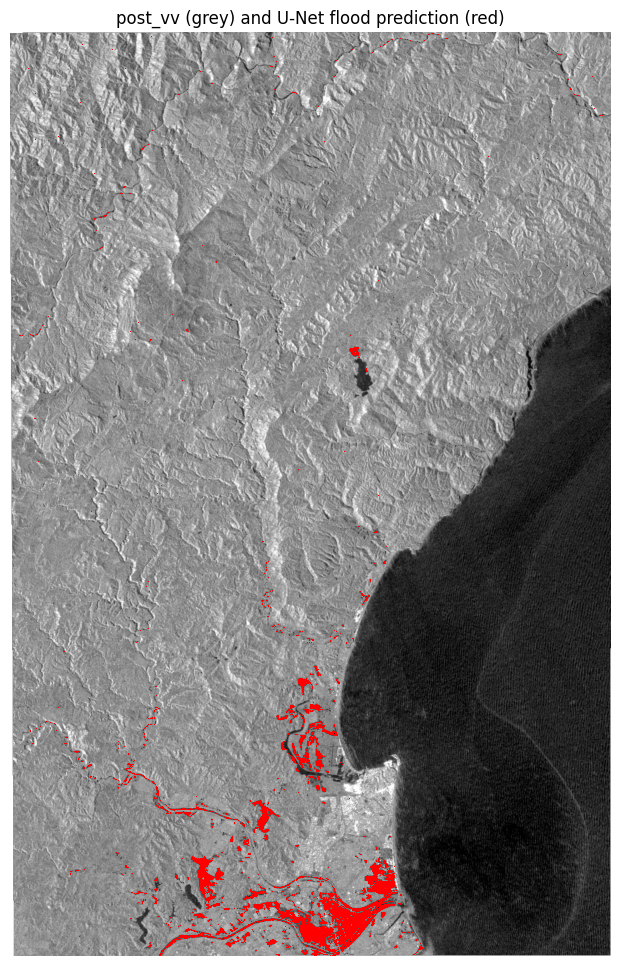

In [10]:
# -------------------------------------------------------------------------
# 7. Quick-Look Map
# -------------------------------------------------------------------------
step = 4  # Downsample for display
post_vv = features[INPUT_BANDS.index('post_vv')][::step, ::step]
flood_view = np.ma.masked_where(flood_binary[::step, ::step] == 0, flood_binary[::step, ::step])

fig, ax = plt.subplots(figsize=(8, 12))
ax.imshow(np.where(valid[::step, ::step], post_vv, np.nan), cmap='gray', vmin=-2.5, vmax=2.5)
ax.imshow(flood_view, cmap='autumn', interpolation='nearest')
ax.set_title('post_vv (grey) and U-Net flood prediction (red)')
ax.axis('off')
plt.savefig(os.path.join(OUTPUT_DIR, 'full_scene_prediction.png'), dpi=150, bbox_inches='tight')
plt.show()

## Step 2: Vectorisation & Road Overlay

The flood raster is turned into polygons and overlaid on the road network to show which roads are under water. All vector outputs are in NZTM2000 (EPSG:2193) so they line up with LINZ and council data in QGIS; the GeoJSON copies are in WGS84, as the GeoJSON format requires.

**Road data:** download the *NZ Road Centrelines (Topo, 1:50k)* layer from [data.linz.govt.nz](https://data.linz.govt.nz) (free account). Crop the export to Hawke's Bay to keep it small, save it as a Shapefile or GeoPackage under `data/linz/`, and set `ROADS_PATH` to match.

In [11]:
# -------------------------------------------------------------------------
# 8. Polygonise the Flood Raster
# -------------------------------------------------------------------------
shapes = rasterio.features.shapes(flood_binary, mask=(flood_binary == 1) & valid, transform=transform)
flood_polygons = gpd.GeoDataFrame(geometry=[shape(geom) for geom, _ in shapes], crs=crs)

n_raw = len(flood_polygons)
flood_polygons = flood_polygons[flood_polygons.area >= MIN_POLYGON_AREA_M2].to_crs(OUTPUT_CRS)
flood_polygons = flood_polygons.reset_index(drop=True)
flood_polygons['area_ha'] = (flood_polygons.area / 1e4).round(2)

print(f"{n_raw} flood polygons, {len(flood_polygons)} kept after removing those under {MIN_POLYGON_AREA_M2} m²")
print(f"Total flooded area in polygons: {flood_polygons['area_ha'].sum() / 100:.1f} km²")

PRODUCT_GPKG = os.path.join(OUTPUT_DIR, 'nzdf_flood_product.gpkg')
flood_polygons.to_file(PRODUCT_GPKG, layer='flood_polygons', driver='GPKG')
flood_polygons.to_crs('EPSG:4326').to_file(os.path.join(OUTPUT_DIR, 'flood_polygons.geojson'), driver='GeoJSON')
print(f"Saved layer 'flood_polygons' to '{PRODUCT_GPKG}' and 'flood_polygons.geojson'")

1421 flood polygons, 1066 kept after removing those under 1000 m²
Total flooded area in polygons: 38.5 km²
Saved layer 'flood_polygons' to 'outputs/nzdf/nzdf_flood_product.gpkg' and 'flood_polygons.geojson'


In [12]:
# -------------------------------------------------------------------------
# 9. Find Flooded Road Segments
# -------------------------------------------------------------------------
scene_area = gpd.GeoSeries([box(*scene_bounds)], crs=crs)
roads_flooded = None

if not os.path.exists(ROADS_PATH):
    print(f"Skipped: no road layer at '{ROADS_PATH}'. Download it from LINZ (see the note above).")
else:
    roads = gpd.read_file(ROADS_PATH, mask=scene_area).to_crs(OUTPUT_CRS)
    roads = roads.clip(scene_area.to_crs(OUTPUT_CRS)).reset_index(drop=True)
    roads['road_id'] = roads.index
    roads['length_m'] = roads.length

    # Roads that touch any flood polygon, then the part of each that lies inside the flooding
    hit_ids = gpd.sjoin(roads, flood_polygons[['geometry']], predicate='intersects')['road_id'].unique()
    flood_union = flood_polygons.union_all()
    roads_flooded = roads[roads['road_id'].isin(hit_ids)].copy()
    roads_flooded['geometry'] = roads_flooded.intersection(flood_union)
    roads_flooded = roads_flooded[~roads_flooded.is_empty]
    roads_flooded['flooded_m'] = roads_flooded.length.round(1)
    roads_flooded['flooded_pct'] = (100 * roads_flooded['flooded_m'] / roads_flooded['length_m']).round(1)

    # Whole roads that are cut somewhere, with how much of each is under water
    roads_affected = roads[roads['road_id'].isin(roads_flooded['road_id'])].merge(
        roads_flooded[['road_id', 'flooded_m', 'flooded_pct']], on='road_id')

    print(f"Roads in scene: {len(roads)} features, {roads['length_m'].sum() / 1000:.0f} km")
    print(f"Roads cut by flooding: {len(roads_affected)} features, "
          f"{roads_flooded['flooded_m'].sum() / 1000:.1f} km under water")

    roads_flooded.to_file(PRODUCT_GPKG, layer='road_segments_flooded', driver='GPKG')
    roads_affected.to_file(PRODUCT_GPKG, layer='roads_affected', driver='GPKG')
    roads_flooded.to_crs('EPSG:4326').to_file(os.path.join(OUTPUT_DIR, 'road_segments_flooded.geojson'),
                                               driver='GeoJSON')
    print(f"Saved layers 'road_segments_flooded' and 'roads_affected' to '{PRODUCT_GPKG}'")

    # Longest flooded stretches first; the name column depends on which LINZ layer was downloaded
    name_col = next((c for c in ('name', 'road_name', 'name_ascii', 'full_road_name') if c in roads_affected), None)
    summary_cols = ([name_col] if name_col else []) + ['length_m', 'flooded_m', 'flooded_pct']
    print(roads_affected.sort_values('flooded_m', ascending=False)[summary_cols].head(15).round(1).to_string())

Skipped: no road layer at '../data/linz/lds-nz-road-centrelines-topo-150k-SHP/nz-road-centrelines-topo-150k.shp'. Download it from LINZ (see the note above).


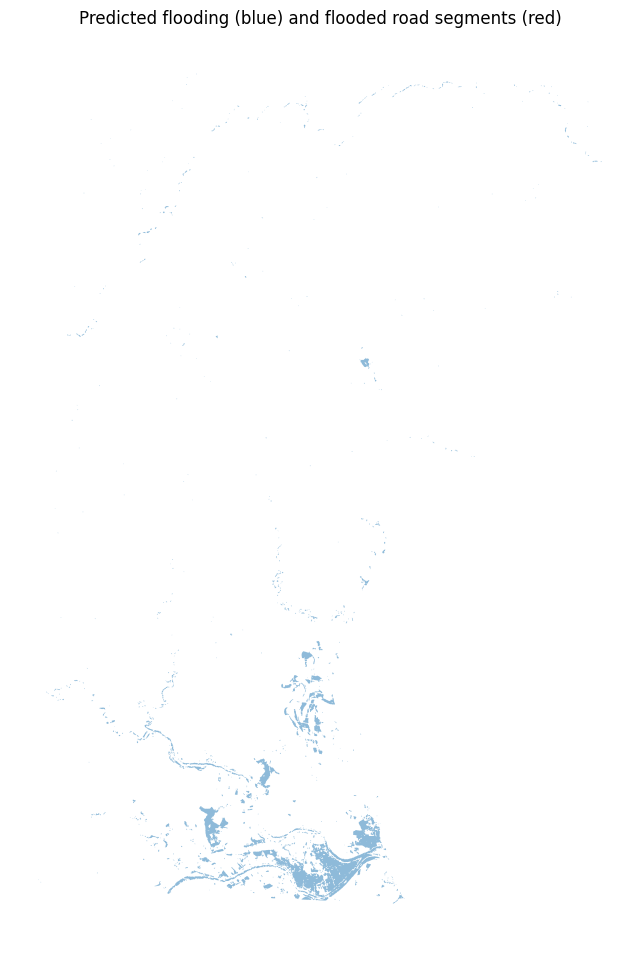

In [13]:
# -------------------------------------------------------------------------
# 10. Road Impact Map
# -------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 12))
flood_polygons.plot(ax=ax, color='tab:blue', alpha=0.5, linewidth=0)
if roads_flooded is not None:
    roads.plot(ax=ax, color='0.6', linewidth=0.5)
    roads_flooded.plot(ax=ax, color='red', linewidth=1.5)
ax.set_title('Predicted flooding (blue) and flooded road segments (red)')
ax.set_axis_off()
plt.savefig(os.path.join(OUTPUT_DIR, 'road_impact_map.png'), dpi=150, bbox_inches='tight')
plt.show()

## Step 3: External Validation

Every score so far compares the model with `baseline_mask`, a −3.5 dB threshold rule that the model can rebuild from its own inputs. Only an independently mapped flood extent shows whether the map finds real flooding.

**Reference data:** the closest official source found is the Hawke's Bay Regional Council [Cyclone Gabrielle flooding map](https://hbrc.govt.nz/our-council/cyclone-gabrielle-response/cyclone-gabrielle-flooding). It has no public download; request the GIS layer from HBRC (Engineering.Enquiries@hbrc.govt.nz). Save it under `data/reference/` and set `REFERENCE_PATH`.

Things to keep in mind when reading the scores:

- **Timing.** The HBRC map is a maximum extent pieced together from photos, video, satellite images and inspections over 13–15 February. The radar image is a single snapshot on 14 February, so water that had drained or not yet arrived counts as a model miss.
- **Mapped area.** Flooding outside the area the reference covers would count as a false positive. If the reference comes with a boundary of the area it mapped, set `REFERENCE_AREA_PATH` to score only inside it.
- **Two rows, not one.** The rule row scores `baseline_mask` itself. The U-Net is only adding value if it beats the rule.
- **Test blocks.** The whole-scene row includes areas the model trained on. The test-blocks row is the fair estimate for unseen ground.

In [19]:
# -------------------------------------------------------------------------
# 11. Score against the Independent Reference
# -------------------------------------------------------------------------
def rasterize_on_scene(gdf):
    """Burn polygons onto the scene grid as a boolean mask."""
    geoms = [g for g in gdf.to_crs(crs).geometry if g is not None and not g.is_empty]
    return rasterio.features.rasterize(((g, 1) for g in geoms), out_shape=(height, width),
                                       transform=transform, fill=0, dtype='uint8').astype(bool)

if not os.path.exists(REFERENCE_PATH):
    print(f"Skipped: no reference flood extent at '{REFERENCE_PATH}' (see the note above).")
else:
    reference = rasterize_on_scene(gpd.read_file(REFERENCE_PATH))
    region = label_valid.copy()
    if REFERENCE_AREA_PATH:
        region &= rasterize_on_scene(gpd.read_file(REFERENCE_AREA_PATH))
    print(f"Reference flooded area: {reference[region].sum() * 100 / 1e6:.1f} km² "
          f"within {region.sum() * 100 / 1e6:.0f} km² scored")

    rows = {
        ('U-Net', 'Whole scene'): flood_metrics(flood_binary, reference, region),
        ('U-Net', 'Test blocks only'): flood_metrics(flood_binary, reference, region & test_blocks),
        ('Rule (baseline_mask)', 'Whole scene'): flood_metrics(pseudo_label, reference, region),
        ('Rule (baseline_mask)', 'Test blocks only'): flood_metrics(pseudo_label, reference, region & test_blocks),
    }
    validation = pd.DataFrame(rows).T.round(3)
    validation.index.names = ['Map', 'Area']
    print(validation)
    validation.to_csv(os.path.join(OUTPUT_DIR, 'external_validation.csv'))

Reference flooded area: 149.2 km² within 2877 km² scored
                                         iou  precision  recall     f1
Map                  Area                                             
U-Net                Whole scene       0.241      0.945   0.244  0.388
                     Test blocks only  0.000      0.000   0.000  0.000
Rule (baseline_mask) Whole scene       0.231      0.928   0.236  0.376
                     Test blocks only  0.000      0.000   0.000  0.000


### Where the Map Misses Flooding

The scores show the map is precise but finds only part of the reference flooding. This cell looks at the missed reference pixels to see why:

- **VV change at missed pixels.** The model learned to find water from a strong VV drop (the −3.5 dB label rule). If missed flooding shows little change or got brighter, the radar did not see open water there on 14 February: it had drained, sat under trees or between buildings (which scatter the signal back brightly), or was covered in silt. If it shows a weak drop, a lower threshold or better labels could recover some of it.
- **Whole areas or edges.** Each reference polygon is grouped by how much of it the map detected. Polygons missed entirely point to areas the radar could not see; polygons detected only partly point to edges trimmed or water that had already receded.
- **Map and layer.** The missed areas are saved as the `reference_missed` layer in the GeoPackage for a closer look in QGIS against aerial imagery.

Reference flooding detected: 36.4 km², missed: 112.8 km²; false alarms outside the reference: 2.1 km²

VV change (post - pre) at reference flood pixels, % of pixels
                             Detected  Missed
Strong drop (< -3.5 dB)          94.9     0.6
Weak drop (-3.5 to -1.5 dB)       5.1    11.8
Little change (±1.5 dB)           0.0    43.0
Brighter (> +1.5 dB)              0.0    44.6
Median VV change: detected -7.2 dB, missed 1.2 dB

155 reference polygons in the scored area, by share detected
                 Polygons  Reference area (km²)
Detected                                       
None (0%)             110                   2.8
Little (0-25%)         31                  76.6
Partly (25-75%)        13                  69.9
Mostly (> 75%)          1                   0.0

Saved layer 'reference_missed' (546 polygons) to 'outputs/nzdf/nzdf_flood_product.gpkg'


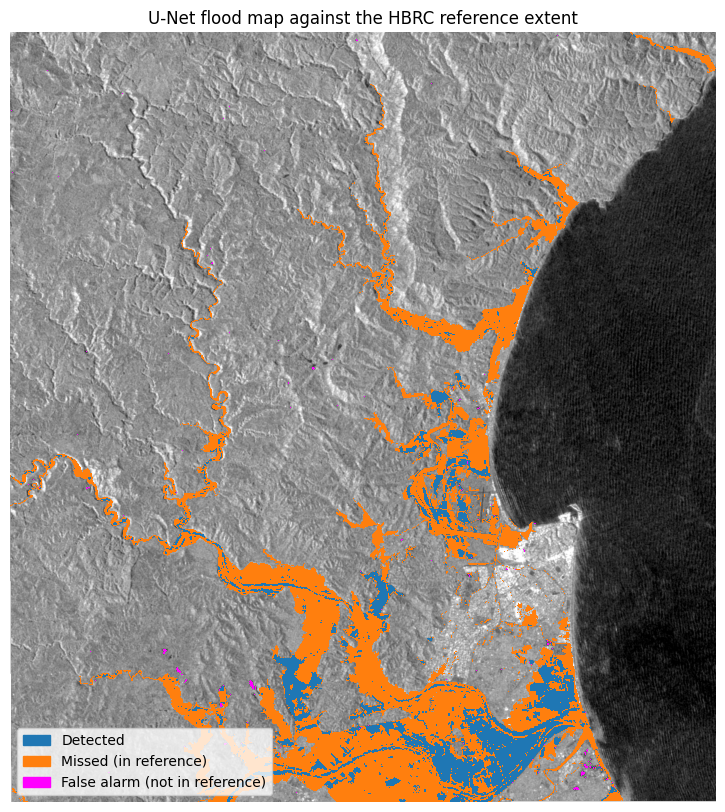

In [20]:
# -------------------------------------------------------------------------
# 12. Where the Map Misses Flooding
# -------------------------------------------------------------------------
if not os.path.exists(REFERENCE_PATH):
    print(f"Skipped: no reference flood extent at '{REFERENCE_PATH}' (see the note above).")
else:
    detected = region & reference & (flood_binary == 1)
    missed = region & reference & (flood_binary == 0)
    false_alarm = region & ~reference & (flood_binary == 1)
    print(f"Reference flooding detected: {detected.sum() * 100 / 1e6:.1f} km², missed: {missed.sum() * 100 / 1e6:.1f} km²; "
          f"false alarms outside the reference: {false_alarm.sum() * 100 / 1e6:.1f} km²")

    # VV change in dB (features are normalised, so undo that first)
    i_pre, i_post = INPUT_BANDS.index('pre_vv'), INPUT_BANDS.index('post_vv')
    vv_change = (features[i_post] * STD[i_post] + MEAN[i_post]) - (features[i_pre] * STD[i_pre] + MEAN[i_pre])
    change_labels = ['Strong drop (< -3.5 dB)', 'Weak drop (-3.5 to -1.5 dB)', 'Little change (±1.5 dB)', 'Brighter (> +1.5 dB)']
    change_table = pd.DataFrame({
        name: 100 * np.bincount(np.digitize(vv_change[mask], [-3.5, -1.5, 1.5]), minlength=4) / mask.sum()
        for name, mask in (('Detected', detected), ('Missed', missed))
    }, index=change_labels).round(1)
    print("\nVV change (post - pre) at reference flood pixels, % of pixels")
    print(change_table.to_string())
    print(f"Median VV change: detected {np.median(vv_change[detected]):.1f} dB, missed {np.median(vv_change[missed]):.1f} dB")

    # Share of each reference polygon the map detected
    reference_polygons = gpd.read_file(REFERENCE_PATH).to_crs(crs)
    reference_polygons = reference_polygons[reference_polygons.geometry.notna() & ~reference_polygons.is_empty]
    polygon_id = rasterio.features.rasterize(
        ((g, i + 1) for i, g in enumerate(reference_polygons.geometry)),
        out_shape=(height, width), transform=transform, fill=0, dtype='int32')
    polygon_id[~region] = 0
    n_ids = len(reference_polygons) + 1
    polygon_px = np.bincount(polygon_id.ravel(), minlength=n_ids)[1:]
    polygon_hit_px = np.bincount(polygon_id[flood_binary == 1], minlength=n_ids)[1:]
    in_scene = polygon_px > 0
    detected_share = pd.cut(polygon_hit_px[in_scene] / polygon_px[in_scene], [-0.01, 0, 0.25, 0.75, 1.0],
                            labels=['None (0%)', 'Little (0-25%)', 'Partly (25-75%)', 'Mostly (> 75%)'])
    polygon_table = (pd.DataFrame({'Detected': detected_share, 'area_km2': polygon_px[in_scene] * 100 / 1e6})
                     .groupby('Detected', observed=False)['area_km2'].agg(['count', 'sum']).round(1))
    polygon_table.columns = ['Polygons', 'Reference area (km²)']
    print(f"\n{in_scene.sum()} reference polygons in the scored area, by share detected")
    print(polygon_table.to_string())

    # Missed areas as polygons, for a closer look in QGIS
    missed_shapes = rasterio.features.shapes(missed.astype(np.uint8), mask=missed, transform=transform)
    missed_polygons = gpd.GeoDataFrame(geometry=[shape(geom) for geom, _ in missed_shapes], crs=crs)
    missed_polygons = missed_polygons[missed_polygons.area >= MIN_POLYGON_AREA_M2].to_crs(OUTPUT_CRS)
    missed_polygons = missed_polygons.reset_index(drop=True)
    missed_polygons['area_ha'] = (missed_polygons.area / 1e4).round(2)
    missed_polygons.to_file(PRODUCT_GPKG, layer='reference_missed', driver='GPKG')
    print(f"\nSaved layer 'reference_missed' ({len(missed_polygons)} polygons) to '{PRODUCT_GPKG}'")

    # Map zoomed to the reference extent
    rows, cols = np.nonzero(reference & region)
    zoom = (slice(rows.min(), rows.max() + 1, 2), slice(cols.min(), cols.max() + 1, 2))
    outcome = np.ma.masked_equal(np.select([detected[zoom], missed[zoom], false_alarm[zoom]], [1, 2, 3], 0), 0)

    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(np.where(valid[zoom], features[i_post][zoom], np.nan), cmap='gray', vmin=-2.5, vmax=2.5)
    ax.imshow(outcome, cmap=ListedColormap(['tab:blue', 'tab:orange', 'magenta']), vmin=1, vmax=3,
              interpolation='nearest')
    ax.legend(handles=[Patch(color='tab:blue', label='Detected'), Patch(color='tab:orange', label='Missed (in reference)'),
                       Patch(color='magenta', label='False alarm (not in reference)')], loc='lower left')
    ax.set_title('U-Net flood map against the HBRC reference extent')
    ax.axis('off')
    plt.savefig(os.path.join(OUTPUT_DIR, 'reference_misses.png'), dpi=150, bbox_inches='tight')
    plt.show()

## Outputs

All files are written to `models/outputs/nzdf/`, which git ignores.

| File | Contents |
| --- | --- |
| `UNet_Full_Scene_Flood_Probability.tif` | Flood probability per pixel, 0–1 (nodata −1) |
| `UNet_Full_Scene_Flood_Prediction.tif` | 1 = flooded, 0 = dry, 255 = nodata |
| `nzdf_flood_product.gpkg` | Layers `flood_polygons`, `road_segments_flooded`, `roads_affected`, `reference_missed` (NZTM2000), ready for QGIS |
| `flood_polygons.geojson`, `road_segments_flooded.geojson` | The same layers in WGS84 |
| `full_scene_prediction.png`, `road_impact_map.png`, `reference_misses.png` | Quick-look maps |
| `external_validation.csv` | Step 3 scores |

detected 36.4 km², missed 112.8 km², false alarm 2.1 km²  (check against notebook cell 12: 35.3 / 113.9 / 2.6)
saved outputs/nzdf/gabrielle_flood_map_runA.pdf


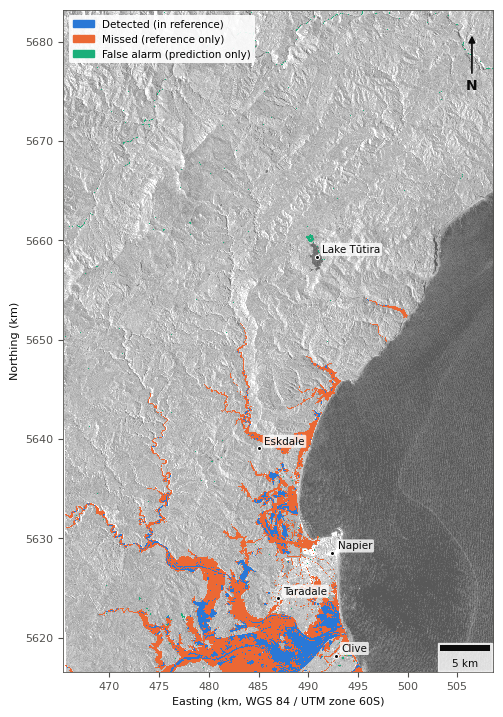

In [22]:
# Report-ready HBRC map for Run A, using the code in gabrielle_map.ipynb
%pip install -q matplotlib-scalebar
import json, re
nb = json.load(open('gabrielle_map.ipynb'))
code = '\n'.join(''.join(c['source']) for c in nb['cells']
                 if c['cell_type'] == 'code' and '%pip' not in ''.join(c['source']))
code = code.replace("os.path.join('..', 'models', 'outputs', 'nzdf',", "os.path.join('outputs', 'nzdf',")
code = code.replace('roads = gpd.read_file(PRODUCT_PATH, layer="road_segments_flooded").to_crs(crs)',
                    'roads = None  # no LINZ road layer in this run')
code = re.sub(r'^roads\.plot\(.*$', '', code, flags=re.M)
code = re.sub(r',\s*Line2D\(\[\], \[\], color=INK, lw=1\.4, label="Flooded road segment"\)\]', ']', code)
code = code.replace("os.path.join('..', 'figures', 'gabrielle_flood_map')",
                    "os.path.join('outputs', 'nzdf', 'gabrielle_flood_map_runA')")
exec(code)